# Customer Churn Prediction Using Deep Learning (Keras)

## 1. Business Understanding

### Business Problem

Customer churn is a major challenge for subscription-based businesses, as losing existing customers can negatively impact recurring revenue and long-term customer value.

A telecommunications company wants to proactively identify customers who are likely to discontinue their services, allowing its retention team to prioritize customers for targeted interventions.

### Project Objective

Develop a binary classification model using Keras to predict customer churn based on demographic information, account characteristics, subscribed services, and billing behavior.

We will compare the performance of a neural network against a Logistic Regression baseline to determine whether deep learning provides additional predictive value.

### Target Variable

- **Churn = Yes (1):** Customer discontinued their service.
- **Churn = No (0):** Customer remained with the company.

### Business Value

Accurate churn predictions can help the company:

- Identify customers at higher risk of leaving.
- Prioritize retention campaigns and outreach.
- Improve customer retention and reduce potential revenue losses.

**Dataset:** IBM Telco Customer Churn — Kaggle.

## 2. Analytical Approach

The analysis will follow a structured machine learning workflow:

1. **Data Understanding:** Examine the dataset's structure, variables, data types, and quality.
2. **Exploratory Data Analysis:** Investigate churn distributions and relationships between customer characteristics and churn.
3. **Data Preprocessing:** Handle missing values, encode categorical features, and scale numerical variables.
4. **Baseline Modeling:** Train a Logistic Regression model to establish a performance benchmark.
5. **Deep Learning:** Build and train a feedforward neural network using Keras.
6. **Model Optimization:** Evaluate overfitting and apply techniques such as dropout and early stopping.
7. **Model Evaluation:** Compare models using precision, recall, F1-score, ROC-AUC, and confusion matrices.
8. **Business Recommendations:** Translate model predictions into actionable customer retention strategies.

### Model Evaluation Strategy

Because our objective is to identify customers at risk of churning, we will pay particular attention to **recall**, which measures the proportion of actual churners correctly identified.

However, recall alone is insufficient. We will also evaluate precision, ROC-AUC, and the trade-off between identifying churners and incorrectly flagging customers who would otherwise remain.

We will use a stratified training, validation, and test split to preserve the churn distribution across datasets. Preprocessing will be fitted using training data only to prevent data leakage.

The final test set will be reserved for evaluating model performance on unseen data.

## 3. Importing Python Libraries

We begin by importing the libraries required for data manipulation, visualization, preprocessing, and deep learning.

- **Pandas / NumPy:** Data manipulation and numerical calculations.
- **Matplotlib / Seaborn:** Exploratory data analysis and visualization.
- **Scikit-learn:** Data preprocessing, baseline modeling, and model evaluation.
- **Keras:** Building and training neural networks.

Additional modeling components will be imported when needed.

In [1]:
# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report)

# Deep Learning
import keras
from keras import layers

# Visualization Settings
sns.set_theme(style = "whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)

In [2]:
# Load the Telco Customer Churn dataset
df = pd.read_csv("C:/Users/GamerTech/Documents/Python/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Display the first five records
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 4. Data Understanding & Quality Assessment

Before performing exploratory analysis or training machine learning models, we need to understand the dataset's structure and assess its quality.

Our initial assessment will focus on:

- **Dataset dimensions:** Number of customers and available features.
- **Data types:** Identifying numerical and categorical variables.
- **Missing values:** Detecting incomplete or incorrectly formatted records.
- **Duplicate records:** Checking whether customers appear multiple times.
- **Target distribution:** Understanding the proportion of customers who churned.

Identifying these issues early will help us determine the appropriate preprocessing steps and avoid introducing errors into our models.

In [3]:
# Dataset Dimensions
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

# Column names and data types
df.info()

# Summary statistics for numerical and categorical features
display(df.describe(include = "all").T)

Rows: 7,043
Columns: 21
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**What are we analyzing?** <br>

The original dataset contains 7,043 customers and 21 columns. <br>

Pay particular attention to:
  - `tenure`: Number of months the customer has been with the company.
  - `MonthlyCharges`: Monthly subscription charges.
  - `TotalCharges`: Total amount charged to the customer.
  - `Contract`: Month-to-month, one-year, or two-year contract.
  - `Churn`: Our target variable.

**Important Observation**: `TotalCharges` is stored as an `object`, even though it represents a numerical amount. This suggests some values may contain non-numeric characters or blank strings. We'll investigate that next.

In [4]:
# Check missing values across all columns
missing_values = df.isna().sum()

print("Missing values by column:")
display(missing_values[missing_values > 0])

# Inspect TotalCharges before conversion
print("TotalCharges data type:", df["TotalCharges"].dtype)

# Identify values that cannot be converted to numbers
invalid_charges = pd.to_numeric(df["TotalCharges"], errors = "coerce").isna()

print("Invalid TotalCharges:", invalid_charges.sum())

# Examine affected records
display(df.loc[invalid_charges])

Missing values by column:


Series([], dtype: int64)

TotalCharges data type: object
Invalid TotalCharges: 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


**Why use** `errors = "coerce"`? 

`pd.to_numeric()` attempts to convert values into numerical data. Setting `errors = "coerce"` converts invalid values into `NaN`, allowing us to identify records that need cleaning. In the original dataset, 11 records contain blank `TotalCharges` values, which a standard `isna()` check doesn't initially detect. We'll decide how to handle these records during preprocessing rather than immediately deleting them.

Duplicate rows: 0
Duplicate customer IDs: 0


,Count,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


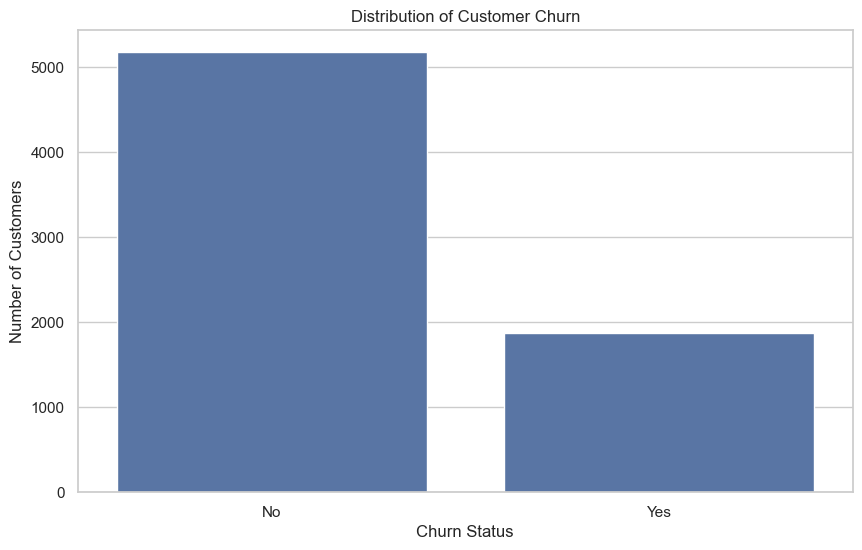

In [5]:
# Check for duplicate rows and customer IDs
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

# Calculate churn distribution
churn_summary = pd.DataFrame({
    "Count": df["Churn"].value_counts(),
    "Percentage": df["Churn"].value_counts(normalize=True) * 100
})

display(churn_summary.round(2))

# Visualize the target distribution
sns.countplot(data=df, x="Churn")

plt.title("Distribution of Customer Churn")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.show()

This tells us our target variable is **moderately imbalanced**. A model that predicts every customer will stay could achieve approximately 73.5% accuracy while identifying no actual churners. That's why accuracy alone won't be sufficient to evaluate our model. We'll pay particular attention to recall, precision, F1-score, and ROC-AUC.

### Initial Data Quality Findings

Our initial assessment identified several important considerations:

1. **Dataset Structure:** The dataset contains 7,043 customer records and 21 variables covering demographics, subscribed services, account information, and churn status.

2. **Missing Values:** Standard missing-value checks do not identify null records. However, `TotalCharges` contains 11 blank entries that prevent numerical conversion.

3. **Duplicate Records:** No duplicate customer IDs or fully duplicated records were identified.

4. **Target Distribution:** Approximately 26.5% of customers churned, compared with 73.5% who remained. This class imbalance means accuracy alone may provide a misleading assessment of model performance.

### Preprocessing Considerations

Before modeling, we will need to:

- Convert `TotalCharges` to a numerical variable and handle its missing values.
- Encode categorical features into numerical representations.
- Scale numerical features where appropriate.
- Exclude `customerID` from the predictive features.
- Split the dataset into training, validation, and test sets before fitting preprocessing transformations to avoid data leakage.

These steps will ensure our data is suitable for Logistic Regression and neural network training.

## 5. Exploratory Data Analysis (EDA)

### Objective

The goal of EDA is to identify patterns and relationships between customer characteristics and churn before developing predictive models.

We will investigate three key questions:

1. **Contract Type:** Are customers on month-to-month contracts more likely to churn than those on longer-term contracts?
2. **Customer Tenure:** Does churn vary depending on how long customers have been with the company?
3. **Monthly Charges:** Are customers paying higher monthly subscription fees more likely to churn?

### Analytical Approach

We'll use visualizations and churn-rate calculations to compare customer groups.

**Churn Rate** = (Number of customers who churned / Total customers in the group) × 100

These findings will help us identify potentially important predictors and develop hypotheses about customer retention.

**Note:** EDA identifies associations, not causal relationships. We cannot conclude that a particular feature causes churn simply because the two are correlated.

,Churn Rate (%)
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83


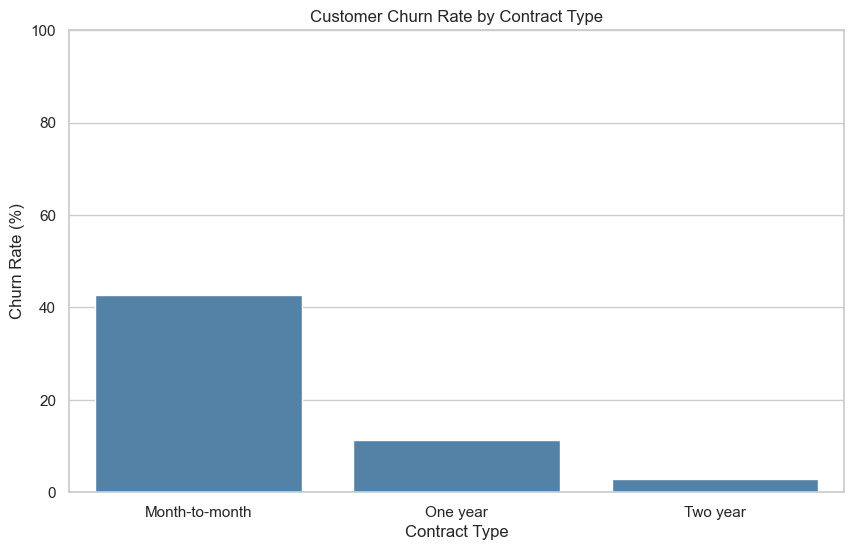

In [6]:
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending = False)
)

display(contract_churn.round(2).to_frame("Churn Rate (%)"))

# Visualize churn rate by contract
sns.barplot(
    x = contract_churn.index,
    y = contract_churn.values,
    color = "steelblue"
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.show()

**What are we analyzing?** <br>
We're calculating the percentage of customers who churned within each contract category, rather than simply counting churned customers. This distinction matters because different contract types may have very different numbers of customers. <br>

In the original dataset, month-to-month customers have a substantially higher churn rate than customers with one-year or two-year contracts. <br>

**Business interpretation**: Contract type may be a strong predictor of churn. The company could investigate whether encouraging longer-term commitments improves retention, although this analysis alone cannot establish that changing contract length would reduce churn.

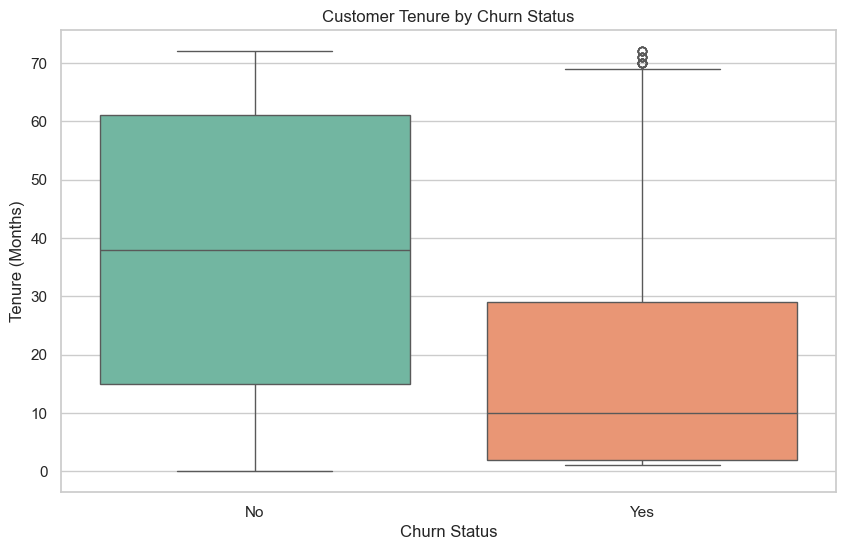

In [7]:
# Compare tenure distributions by churn status
sns.boxplot(
    data = df,
    x = "Churn",
    y = "tenure",
    hue = "Churn",
    palette = "Set2",
    legend = False
)

plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.show()

# Compare median tenure
tenure_summary = df.groupby("Churn")["tenure"].agg(
    ["mean", "median", "count"]
)

**Why use a box plot?**<br>

A box plot helps us compare the distributions of customer tenure across churn groups, including:
- Median: Typical customer tenure.
- Interquartile range: The middle 50% of tenure values.
- Outliers: Unusually short or long customer relationships. <br>

We expect customers who churned to have shorter tenure on average. <br>

**Business interpretation**: If churn is concentrated among newer customers, the company may benefit from investigating early customer experiences, onboarding, and initial service satisfaction. However, remember that tenure measures how long a customer has remained with the company; it is not necessarily a direct measure of customer satisfaction.

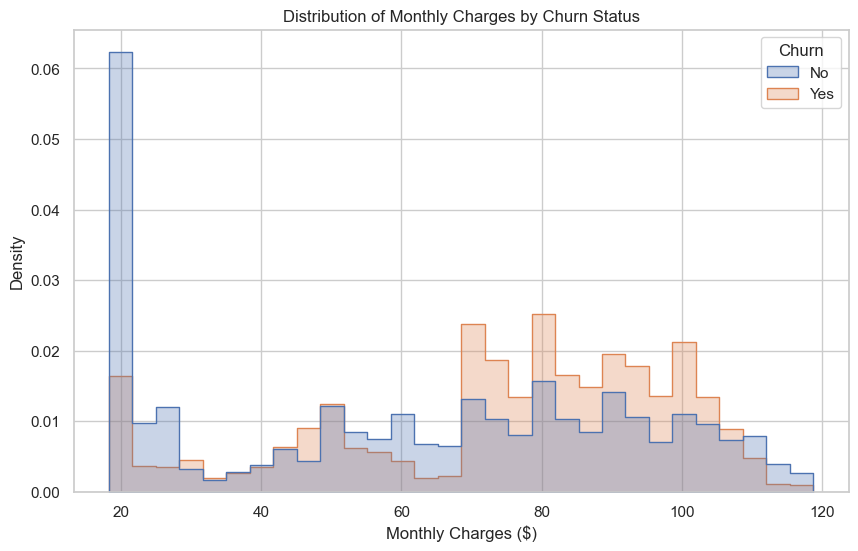

,mean,median,count
Churn,,,
No,61.27,64.43,5174
Yes,74.44,79.65,1869


In [8]:

# Compare monthly charge distributions
sns.histplot(
    data=df,
    x="MonthlyCharges",
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    element="step",
    alpha=0.3
)

plt.title("Distribution of Monthly Charges by Churn Status")
plt.xlabel("Monthly Charges ($)")
plt.ylabel("Density")
plt.show()

# Compare average and median monthly charges
charges_summary = df.groupby("Churn")["MonthlyCharges"].agg(
    ["mean", "median", "count"]
)

display(charges_summary.round(2))


**Why use `common_norm = False`?** <br>

There are more customers who stayed than customers who churned. Using `common_norm=False` normalizes each group's distribution separately, making it easier to compare the shape of monthly charges across the two groups without the larger group dominating the visualization. <br>

**Business interpretation**: If customers who churn have higher monthly charges, pricing or perceived value may be associated with retention. But higher charges could also reflect differences in service packages, contract types, or customer segments. We'll need multivariable modeling to assess whether monthly charges remain predictive after accounting for other features.

### Initial EDA Findings

Our analysis focuses on three potential drivers of customer churn:

**1. Contract Type**

Month-to-month customers exhibit substantially higher churn rates than customers with longer-term contracts. This suggests contract type may be an important predictor of customer retention.

**2. Customer Tenure**

Customers who churn tend to have shorter tenure than customers who remain. This suggests that early customer relationships may warrant closer investigation.

**3. Monthly Charges**

Customers who churn tend to have higher monthly charges on average. However, the relationship may be influenced by differences in contract type, service subscriptions, or other customer characteristics.

### Business Implications

These patterns suggest three areas worth investigating:

- **Early retention:** Evaluate onboarding experiences and engagement during the first months of a customer's relationship.
- **Contract strategy:** Investigate whether incentives for longer-term contracts are associated with improved retention.
- **Pricing and value:** Examine whether particular customer segments experience higher churn at higher subscription prices.

### Implications for Machine Learning

Contract type, tenure, and monthly charges are promising predictive features.

However, exploratory relationships do not guarantee predictive importance. We will assess their contribution through model training, evaluation, and interpretability techniques.

All findings should be validated using the actual dataset outputs before being treated as final conclusions.

## 6. Deeper Exploratory Data Analysis

### Objective

We previously identified associations between churn and three customer characteristics: contract type, tenure, and monthly charges.

However, churn is rarely explained by a single feature.

In this section, we'll investigate:

1. **Internet Service:** Do churn rates differ between DSL, fiber optic, and customers without internet service?
2. **Additional Services:** Are customers subscribed to OnlineSecurity or TechSupport less likely to churn?
3. **Payment Method:** Are certain payment methods associated with higher churn?
4. **Feature Interactions:** Does the relationship between contract type and churn differ across internet service categories?

### Why examine feature interactions?

A feature's relationship with churn may depend on another feature.

For example, fiber optic customers might have higher churn overall, but this could partly reflect differences in their contract types.

By examining combinations of features, we can identify patterns that may not be apparent when analyzing each variable independently.

These findings can also guide feature engineering and model interpretation later in the project.

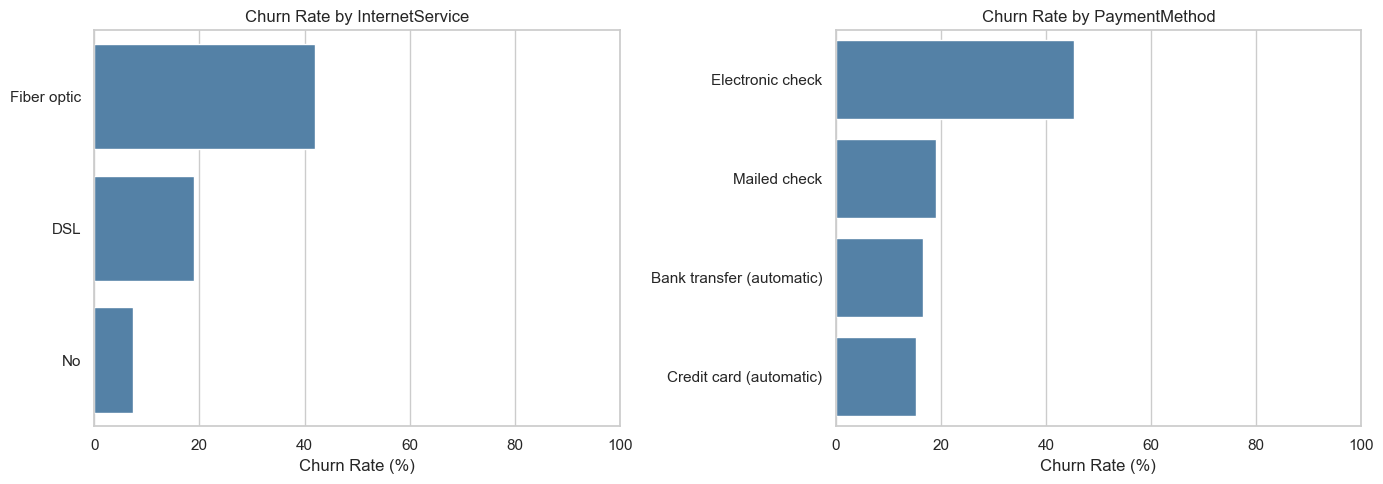

In [11]:

# Convert churn into a binary indicator for EDA
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

features = ["InternetService", "PaymentMethod"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, feature in zip(axes, features):
    churn_rates = (
        df.groupby(feature)["ChurnFlag"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    sns.barplot(
        x=churn_rates.values,
        y=churn_rates.index,
        color="steelblue",
        ax=ax
    )

    ax.set_title(f"Churn Rate by {feature}")
    ax.set_xlabel("Churn Rate (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, 100)

plt.tight_layout()
plt.show()


**What we should look for?**

**Internet Service**: Does fiber optic service have a higher churn rate than DSL? If so, could this reflect differences in pricing, service quality, or customer demographics?

**Payment Method**: Do customers using electronic checks have higher churn than those using automatic payments?

The key distinction is that these are **associations, not proof of causation**.

For example, customers using automatic payments might also have longer contracts, which could explain part of the difference in churn rates.

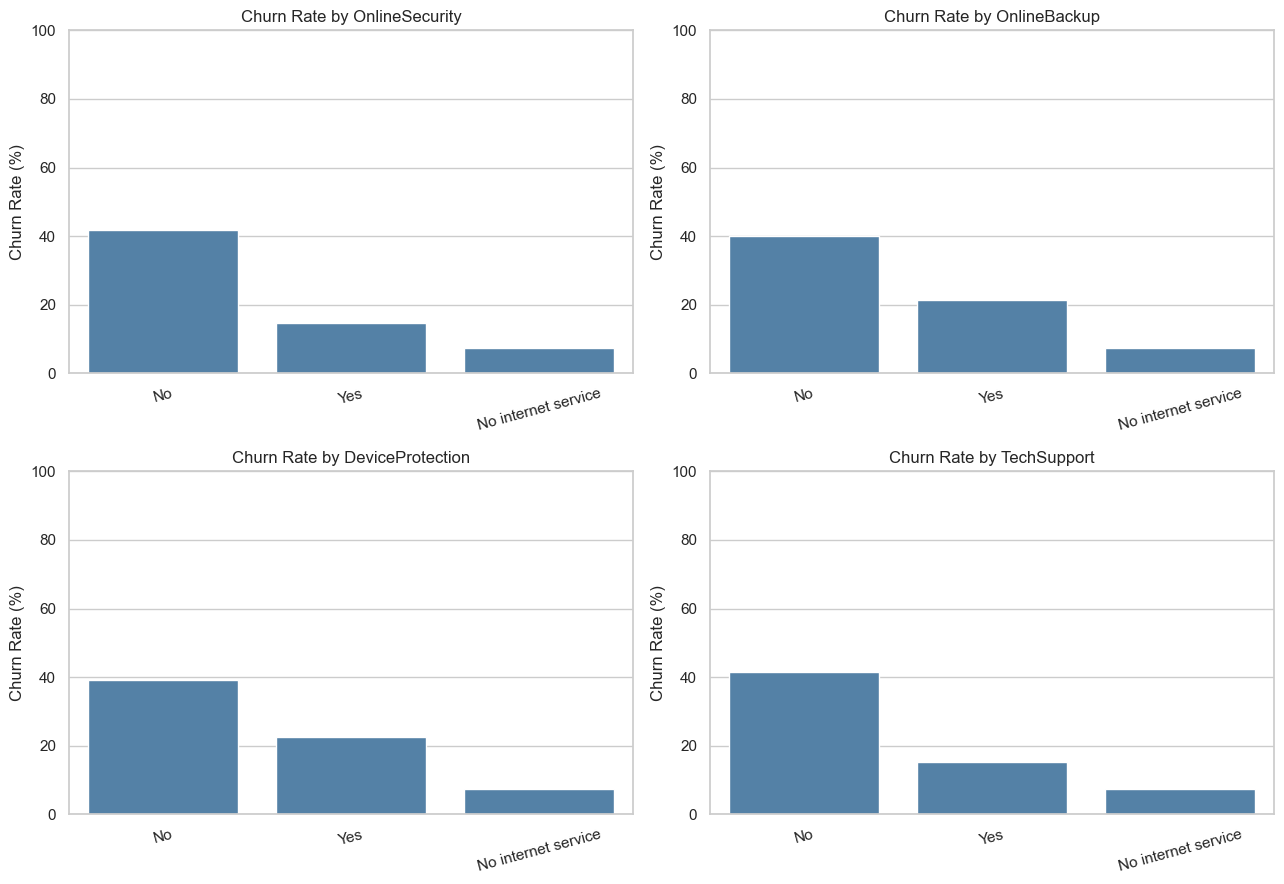

In [12]:
service_features = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport"
]

# Calculate churn rates for each service category
service_churn = (
    df.groupby(service_features)["ChurnFlag"]
    .agg(["mean", "count"])
)

# Display each feature separately for easier interpretation
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, feature in zip(axes.flat, service_features):
    rates = (
        df.groupby(feature)["ChurnFlag"]
        .mean()
        .mul(100)
        .sort_values(ascending = False)
    )

    sns.barplot(
        x = rates.index,
        y = rates.values,
        color = "steelblue",
        ax = ax
    )

    ax.set_title(f"Churn Rate by {feature}")
    ax.set_xlabel("")
    ax.set_ylabel("Churn Rate (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis = "x", rotation = 15)

plt.tight_layout()
plt.show()

**Why examine additional services?**

Customers subscribing to security, backup, or technical support services may behave differently from customers without these subscriptions.

Potential explanations include:
- Greater perceived value from bundled services.
- Different customer needs and subscription preferences.
- Differences in contract length or customer tenure.

**Important**: The category No internet service is not equivalent to a customer declining an optional add-on. Keep that distinction in mind when interpreting these plots. We are not yet determining whether these features improve prediction. That will come during model evaluation.

InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,32.22,54.61,18.89
One year,9.30,19.29,2.47
Two year,1.91,7.23,0.78


InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,1223,2128,524
One year,570,539,364
Two year,628,429,638


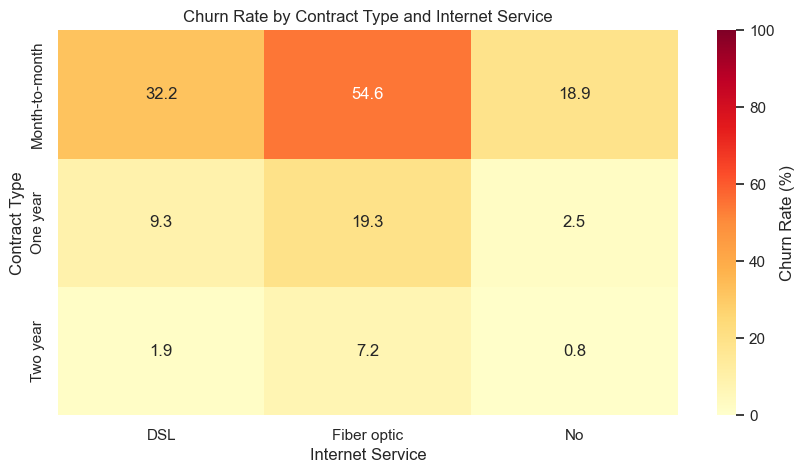

In [14]:

# Calculate churn rate for each feature combination
interaction_rates = (
    df.pivot_table(
        index = "Contract",
        columns = "InternetService",
        values = "ChurnFlag",
        aggfunc = "mean"
    ) * 100
)

# Check group sizes to avoid overinterpreting small segments
interaction_counts = pd.crosstab(
    df["Contract"],
    df["InternetService"]
)

display(interaction_rates.round(2))
display(interaction_counts)

# Visualize churn-rate differences
plt.figure(figsize=(10, 5))

sns.heatmap(
    interaction_rates,
    annot = True,
    fmt = ".1f",
    cmap = "YlOrRd",
    vmin = 0,
    vmax = 100,
    cbar_kws = {"label": "Churn Rate (%)"}
)

plt.title("Churn Rate by Contract Type and Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Contract Type")
plt.show()

**Why use a heatmap?**

A heatmap helps us examine two categorical features simultaneously. For example, we might discover that month-to-month fiber optic customers have particularly high churn rates, while two-year contract customers have low churn rates across internet service categories.

This provides a more nuanced understanding than looking at internet service or contract type alone. We also calculate group sizes, because a high churn rate based on very few customers is less reliable than one based on a large group.

### Deeper EDA: Findings and Interpretation

Our analysis investigates how service subscriptions, payment methods, and combinations of customer characteristics relate to churn.

**1. Internet Service**

Compare churn rates across fiber optic, DSL, and customers without internet service.

If one service category has consistently higher churn, investigate whether pricing, contract mix, or other customer characteristics could explain the difference.

**2. Additional Services**

Examine whether customers subscribed to OnlineSecurity, OnlineBackup, DeviceProtection, and TechSupport have different churn rates.

These relationships may indicate differences in customer engagement or perceived service value, but they do not establish that subscribing to an additional service prevents churn.

**3. Payment Method**

Identify whether certain payment methods are associated with higher churn.

Consider whether these differences might reflect customer tenure, contract type, or billing preferences.

**4. Feature Interactions**

Use the contract-type and internet-service heatmap to identify customer segments with particularly high or low churn rates.

Pay attention to the number of customers within each segment before interpreting its churn rate.

### Implications for Machine Learning

These findings suggest several useful predictive features:

- Internet service category
- Payment method
- Additional service subscriptions
- Contract type
- Potential interactions between categorical features

We will initially allow our neural network to learn relationships between these variables. We can later test whether explicitly engineered interaction features improve the simpler baseline models.

**Important:** These are exploratory findings, not validated predictive results. We will assess model performance on held-out data and avoid making causal claims from observational patterns.

## 7. Data Preprocessing & Dataset Splitting

### Objective

Our goal is to transform the customer data into a format suitable for Logistic Regression and Keras neural networks while preventing data leakage.

We'll follow five steps:

1. **Clean numerical data:** Convert `TotalCharges` into a numerical feature and handle missing values.
2. **Separate predictors and target:** Remove customer identifiers and target-derived columns.
3. **Split the dataset:** Create training, validation, and test sets.
4. **Encode categorical features:** Convert categorical values into numerical representations using One-Hot Encoding.
5. **Scale numerical features:** Standardize numerical variables to improve model training.

### Why is data leakage important?

Data leakage occurs when information unavailable at prediction time influences model training or evaluation.

For example, calculating scaling parameters using the entire dataset would allow information from validation and test customers to influence our preprocessing.

To prevent this, we'll split the data **before fitting any imputation, encoding, or scaling transformations**.

Our intended dataset allocation is:

- **Training (70%):** Fit models and preprocessing transformations.
- **Validation (15%):** Compare models, tune hyperparameters, and select classification thresholds.
- **Test (15%):** Evaluate the final selected model on unseen data.

We'll use stratified splitting to maintain approximately the same churn distribution across all three datasets.

In [15]:
# Create a separate modeling dataset
model_df = df.copy()

# Convert TotalCharges to numeric; invalid entries become NaN
model_df["TotalCharges"] = pd.to_numeric(
    model_df["TotalCharges"], errors = "coerce"
)

# Define binary target: 1 = churned, 0 =  retained
y = (model_df["Churn"] == "Yes").astype(int)

# Exclude identifiers and all target-derived columns
X = model_df.drop(
    columns = ["customerID", "Churn", "ChurnFlag"],
    errors = "ignore"
)

print("Feature matrix:", X.shape)
print("Target vector:", y.shape)
print("Missing TotalCharges:", X["TotalCharges"].isna().sum())
print("Target distribution:")
display(y.value_counts(normalize = True).round(3))

Feature matrix: (7043, 19)
Target vector: (7043,)
Missing TotalCharges: 11
Target distribution:


Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

**Why are we doing this?**

- `TotalCharges`: The original dataset contains 11 blank values. We convert these into NaN and will impute them using training-set statistics.
- `customerID`: An identifier rather than a meaningful customer behavior feature.
- `Churn`: The original target column.
- `ChurnFlag`: The binary target-derived column we created during EDA.

Keeping either target column inside X would introduce serious data leakage. Notice that we haven't imputed the missing values yet. That will happen inside our preprocessing pipeline after splitting the data.

In [17]:
# First split: 70% training, 30% temporary holdout
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size = 0.30,
    stratify = y,
    random_state = 42
)

# Second split: divide holdout into validation and test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size = 0.50,
    stratify = y_temp,
    random_state = 42
)

# Verify dataset sizes and churn proportions
split_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Customers": [len(y_train), len(y_val), len(y_test)],
    "Churn Rate (%)": [
        y_train.mean() * 100,
        y_val.mean() * 100,
        y_test.mean() * 100
    ]
})

display(split_summary.round(2))

,Dataset,Customers,Churn Rate (%)
0,Train,4930,26.53
1,Validation,1056,26.52
2,Test,1057,26.58


**Why stratify?**

We discovered earlier that approximately 26.5% of customers churned. Without stratification, random splitting could produce datasets with noticeably different churn proportions. Using `stratify = y` helps preserve the target distribution, making model comparisons more reliable.

**Why three datasets instead of two?**

Training: Learn model parameters. Validation: Tune models and select thresholds. TesT: Final unbiased performance estimate

The test set should remain untouched until we've finalized our modeling decisions.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# SeniorCitizen is a binary category, not a continuous measure
categorical_features = X_train.select_dtypes(
    include = ["object", "category"]
).columns.tolist() + ["SeniorCitizen"]

numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

# Numerical preprocessing: impute and standardize
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing: impute and one-hot encode
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy = "most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown = "ignore",
        sparse_output = False
    ))
])

# Combine transformations
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'SeniorCitizen']


### Why These Transformations?

#### 1. Median Imputation

We use the median to replace missing numerical values because it is less sensitive to extreme values than the mean.

#### 2. StandardScaler

Neural networks and Logistic Regression generally benefit from numerical features being on comparable scales.

The transformation is:

$$
z = \frac{x-\mu}{\sigma}
$$

where $\mu$ and $\sigma$ are calculated using the training dataset.

#### 3. One-Hot Encoding

Features such as `Contract` and `InternetService` contain categories rather than continuous numerical values.

One-Hot Encoding creates separate binary columns without imposing an artificial numerical order.

#### 4. `handle_unknown="ignore"`

This prevents errors when validation or test data contain categories not observed during training.

In [21]:

# Learn preprocessing parameters from training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Verify transformed dimensions
print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)

# Verify no missing or infinite values remain
for name, data in [
    ("Train", X_train_processed),
    ("Validation", X_val_processed),
    ("Test", X_test_processed)
]:
    print(
        f"{name}:",
        "Missing =", np.isnan(data).sum(),
        "Infinite =", np.isinf(data).sum()
    )

# Inspect the final feature names
feature_names = preprocessor.get_feature_names_out()
display(pd.DataFrame({"Feature": feature_names}))


Train: (4930, 46)
Validation: (1056, 46)
Test: (1057, 46)
Train: Missing = 0 Infinite = 0
Validation: Missing = 0 Infinite = 0
Test: Missing = 0 Infinite = 0


,Feature
0,numeric__tenure
1,numeric__MonthlyCharges
2,numeric__TotalCharges
3,categorical__gender_Female
4,categorical__gender_Male
5,categorical__Partner_No
6,categorical__Partner_Yes
7,categorical__Dependents_No
8,categorical__Dependents_Yes
9,categorical__PhoneService_No


**Why `fit_transform()` for training but `transform()` for validation and test?**

This is one of the most important distinctions in the entire project.
- fit_transform(X_train) learns the training data's medians, means, standard deviations, and categorical encodings, then applies them.
- transform(X_val) and transform(X_test) reuse those learned parameters without recalculating them.

This prevents the validation and test datasets from influencing the preprocessing process. The output is a numerical feature matrix ready for Scikit-learn and Keras.

## 8. Baseline Model: Logistic Regression

### Objective

Our first model will predict the probability that a customer will churn using Logistic Regression.

Despite its name, Logistic Regression is a **classification algorithm** commonly used for binary outcomes.

For each customer, the model estimates:

$$
P(\text{Churn}=1 \mid X)
$$

where $X$ represents the customer's characteristics.

### Why Logistic Regression?

We selected Logistic Regression because:

1. **Interpretability:** Model coefficients help explain how individual features relate to predicted churn risk.
2. **Efficiency:** It trains quickly and works well with one-hot encoded categorical variables.
3. **Probability Estimates:** It produces churn probabilities that can support risk-based customer prioritization.
4. **Baseline Comparison:** It provides a benchmark for determining whether a more complex neural network adds predictive value.

### Evaluation Strategy

Because approximately 26.5% of customers churn, accuracy alone is insufficient.

We'll evaluate:

- **Precision:** Of customers predicted to churn, how many actually churned?
- **Recall:** Of customers who actually churned, how many did we identify?
- **F1-score:** Harmonic mean of precision and recall.
- **ROC-AUC:** How well the model distinguishes churners from non-churners across classification thresholds.

We'll initially use a classification threshold of **0.50** and evaluate performance on the validation dataset.

The test dataset will remain untouched until final model selection.

In [22]:

# Initialize Logistic Regression
log_reg = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train using the processed training data
log_reg.fit(X_train_processed, y_train)

# Generate churn probabilities on validation data
y_val_proba_lr = log_reg.predict_proba(
    X_val_processed
)[:, 1]

# Convert probabilities to binary predictions
y_val_pred_lr = (y_val_proba_lr >= 0.50).astype(int)

print("Logistic Regression training complete.")
print("Validation predictions:", len(y_val_pred_lr))

Logistic Regression training complete.
Validation predictions: 1056


**Why these settings?**

`max_iter=1000`: Increases the maximum number of optimization iterations, helping the model converge.

`random_state=42`:  Provides reproducibility where randomness is involved.

`predict_proba()[:, 1]`:  Returns the estimated probability of the positive class (`Churn = 1`). For example, a predicted probability of 0.78 indicates that the model estimates a 78% probability of churn.

**Why use 0.50?**
It's a conventional starting threshold, not necessarily the optimal one. Later, we'll investigate whether a different threshold produces a better balance between precision and recall.

In [23]:

# Calculate baseline validation metrics
lr_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred_lr),
    "Precision": precision_score(y_val, y_val_pred_lr),
    "Recall": recall_score(y_val, y_val_pred_lr),
    "F1 Score": f1_score(y_val, y_val_pred_lr),
    "ROC-AUC": roc_auc_score(y_val, y_val_proba_lr)
}

lr_results = pd.DataFrame(
    lr_metrics.items(),
    columns = ["Metric", "Score"]
)

display(lr_results.round(4))

# Detailed classification report
print(classification_report(
    y_val,
    y_val_pred_lr,
    target_names = ["Retained", "Churned"]
))


,Metric,Score
0,Accuracy,0.8059
1,Precision,0.6459
2,Recall,0.5929
3,F1 Score,0.6182
4,ROC-AUC,0.8453


              precision    recall  f1-score   support

    Retained       0.86      0.88      0.87       776
     Churned       0.65      0.59      0.62       280

    accuracy                           0.81      1056
   macro avg       0.75      0.74      0.74      1056
weighted avg       0.80      0.81      0.80      1056



**How should we interpret these metrics?**

Suppose a model achieves:
- Precision = 0.65
- Recall = 0.75

That would mean:
- Of customers the model flagged as likely to churn, **65% actually churned**.
- Of all customers who churned, the model successfully identified **75%**.

These are illustrative numbers, not actual results from our dataset.

**Which metric should we prioritize?**
That depends on the business objective. If retention outreach is relatively inexpensive, higher recall may be desirable because we want to identify more at-risk customers. If outreach is costly, precision becomes more important because false positives consume resources. We'll revisit this trade-off when optimizing our classification threshold.

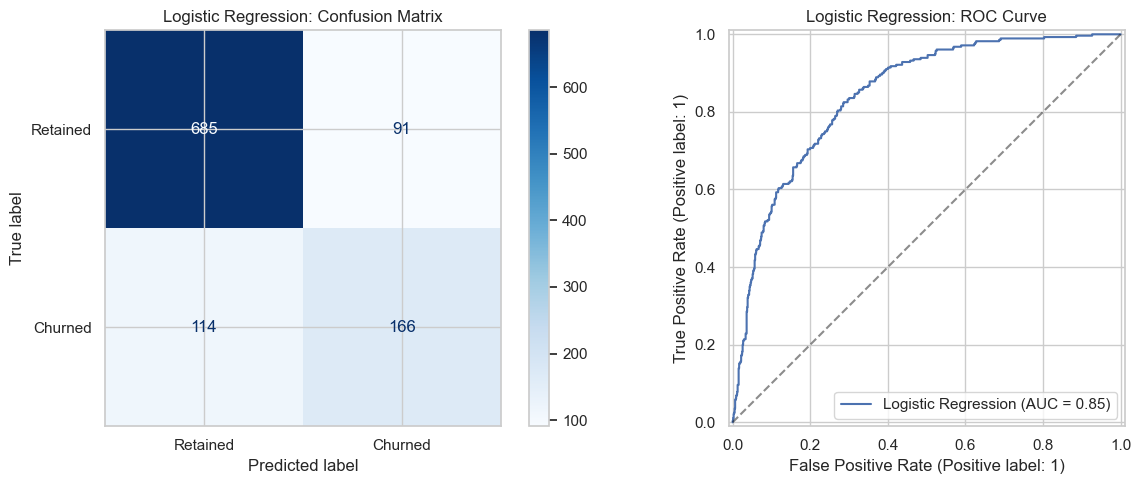

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion matrix at the 0.50 threshold
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_lr,
    display_labels = ["Retained", "Churned"],
    cmap = "Blues",
    ax = axes[0]
)

axes[0].set_title("Logistic Regression: Confusion Matrix")

# ROC Curve using predicted probabilities
RocCurveDisplay.from_predictions(
    y_val,
    y_val_proba_lr,
    name = "Logistic Regression",
    ax = axes[1]
)

axes[1].plot([0, 1], [0, 1], "k--", alpha = 0.5)
axes[1].set_title("Logistic Regression: ROC Curve")

plt.tight_layout()
plt.show()

### Understanding the Confusion Matrix

A confusion matrix compares **predicted vs. actual customer churn**.

| | Predicted Retained | Predicted Churn |
|---|---|---|
| **Actually Retained** | True Negative (TN) | False Positive (FP) |
| **Actually Churned** | False Negative (FN) | True Positive (TP) |

**Definitions:**

- **True Negative (TN):** Predicted retained; actually retained.
- **False Positive (FP):** Predicted churn; actually retained.
- **False Negative (FN):** Predicted retained; actually churned.
- **True Positive (TP):** Predicted churn; actually churned.

### Business Interpretation

In a churn prediction context:

- **False Negatives:** At-risk customers the model fails to identify.
- **False Positives:** Customers who would remain but are incorrectly flagged for retention outreach.

### Understanding the ROC Curve

The ROC curve measures how effectively the model separates churners from non-churners across different classification thresholds.

**ROC-AUC Interpretation:**

- **0.50:** Chance-level ranking performance.
- **1.00:** Perfect separation between churners and non-churners.

A higher ROC-AUC generally indicates better discrimination between the two customer groups.

### Logistic Regression: Baseline Model Assessment

We trained a Logistic Regression model using the preprocessed training dataset and evaluated it on the validation dataset.

### Key Evaluation Questions

**1. Predictive Performance**

- How well does the model distinguish churners from retained customers?
- Does its ROC-AUC suggest useful discrimination?
- How does its accuracy compare with a majority-class baseline?

**2. Precision vs. Recall**

- How many actual churners are correctly identified?
- How many customers are incorrectly flagged as likely to churn?
- Which type of classification error is more costly to the business?

**3. Business Application**

The model produces customer-level churn probabilities that could help prioritize retention outreach.

However, predicted churn risk does not tell us whether a customer would respond positively to a retention offer. Measuring the incremental impact of outreach would require additional experimentation or causal analysis.

### Next Steps

We will use Logistic Regression as our baseline for evaluating the Keras neural network.

Our goal is to determine whether the neural network delivers meaningful improvements in predictive performance while considering model complexity and interpretability.

We will also investigate classification threshold optimization before making final business recommendations.

## 9. Building a Neural Network with Keras

### Objective

We'll build a feedforward Artificial Neural Network (ANN) to predict customer churn.

Unlike Logistic Regression, which models a linear relationship in the log-odds of churn, neural networks can learn more complex, nonlinear relationships between customer characteristics.

### Proposed Architecture

Our neural network will contain:

1. **Input Layer:** Receives the preprocessed customer features.
2. **Hidden Layer 1:** 32 neurons with ReLU activation.
3. **Hidden Layer 2:** 16 neurons with ReLU activation.
4. **Output Layer:** 1 neuron with Sigmoid activation.

### Why these choices?

- **ReLU:** Introduces nonlinearity, allowing the network to learn complex relationships.
- **Sigmoid:** Produces an output between 0 and 1, representing the estimated probability of churn.
- **Binary Cross-Entropy:** Measures prediction error for binary classification.
- **Adam Optimizer:** Adjusts model weights using adaptive learning rates.

We'll begin with a relatively small network because our dataset contains approximately 7,000 customers. A larger architecture could increase the risk of overfitting without improving predictive performance.

We'll compare this model against Logistic Regression to determine whether additional complexity provides meaningful benefits.

In [25]:
# Set seed for reproducibility
keras.utils.set_random_seed(42)

# Define the neural network architecture
nn_model = keras.Sequential([
    keras.Input(shape = (X_train_processed.shape[1],)),
    layers.Dense(32, activation = "relu"),
    layers.Dense(16, activation = "relu"),
    layers.Dense(1, activation = "sigmoid")
])

# Configure the learning process
nn_model.compile(
    optimizer = keras.optimizers.Adam(learning_rate = 0.001),
    loss = "binary_crossentropy",
    metrics = [
        keras.metrics.BinaryAccuracy(name = "accuracy"),
        keras.metrics.AUC(name = "auc")
    ]
)

# Display architecture and parameter counts
nn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,049 (8.00 KB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 0 (0.00 B)

**Understanding the code**

- `keras.Sequential()` creates a neural network where layers are arranged sequentially.
- `Dense(32, activation="relu")` defines a fully connected hidden layer with 32 neurons.
- `Dense(1, activation="sigmoid")` produces a single churn probability.
- `learning_rate=0.001` controls the size of the optimizer's weight updates. This is a common starting value for Adam.
- `binary_crossentropy` penalizes incorrect probability predictions, especially confident incorrect predictions.
  
**Why track AUC?** Because our classes are imbalanced, discrimination performance is useful to monitor alongside accuracy.

### Neural Network Training Strategy

Training involves repeatedly passing customer data through the network and adjusting its weights to reduce prediction error.

We will use three important training settings.

**1. Epochs**

An epoch represents one complete pass through the training dataset.

We'll allow a maximum of 100 epochs, but training may stop earlier if validation performance stops improving.

**2. Batch Size**

We'll use a batch size of 32, meaning the model processes 32 customer records before performing a weight update.

Smaller batches produce more frequent updates, while larger batches can improve computational efficiency.

**3. Early Stopping**

Neural networks can overfit by learning patterns specific to the training dataset rather than generalizable relationships.

We'll monitor validation loss and stop training when it stops improving for several consecutive epochs.

We'll also restore the weights from the epoch with the lowest validation loss.

### Why use validation loss?

Validation loss evaluates how well the model predicts probabilities on data that was not used to update its weights.

If training loss continues decreasing while validation loss increases, that may indicate overfitting.

Our test dataset will remain untouched until final model evaluation.

In [26]:
# Stop training if validation loss stops improving
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train the neural network
history = nn_model.fit(
    X_train_processed,
    y_train.to_numpy(),
    validation_data=(
        X_val_processed,
        y_val.to_numpy()
    ),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print("Epochs completed:", len(history.history["loss"]))


Epoch 1/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7696 - auc: 0.7839 - loss: 0.4761 - val_accuracy: 0.7898 - val_auc: 0.8336 - val_loss: 0.4311
Epoch 2/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7990 - auc: 0.8410 - loss: 0.4220 - val_accuracy: 0.7964 - val_auc: 0.8407 - val_loss: 0.4224
Epoch 3/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8049 - auc: 0.8456 - loss: 0.4164 - val_accuracy: 0.7936 - val_auc: 0.8423 - val_loss: 0.4208
Epoch 4/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8057 - auc: 0.8481 - loss: 0.4134 - val_accuracy: 0.8002 - val_auc: 0.8427 - val_loss: 0.4204
Epoch 5/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8067 - auc: 0.8497 - loss: 0.4115 - val_accuracy: 0.7973 - val_auc: 0.8429 - val_loss: 0.4200
Epoch 6/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8099 - auc: 0.8511 - loss: 0.4097 - val_accuracy: 0.7955 - val_auc: 0.8426 - val_loss: 0.4205
Epoch 7/100
155/155 ━━━━━━━━━━━━━━

**Why these parameters?**
- `monitor="val_loss"`: Monitors performance on the validation dataset.
- `patience=10`: Allows 10 consecutive epochs without improvement before stopping.
- `restore_best_weights=True`: Restores the model weights associated with the lowest validation loss.
- `validation_data`: Evaluates the model after each epoch without updating its weights using validation records.

Early stopping helps control overfitting and avoids unnecessary training.
One important distinction: validation data influences when training stops, but it is not used directly to calculate gradient updates.

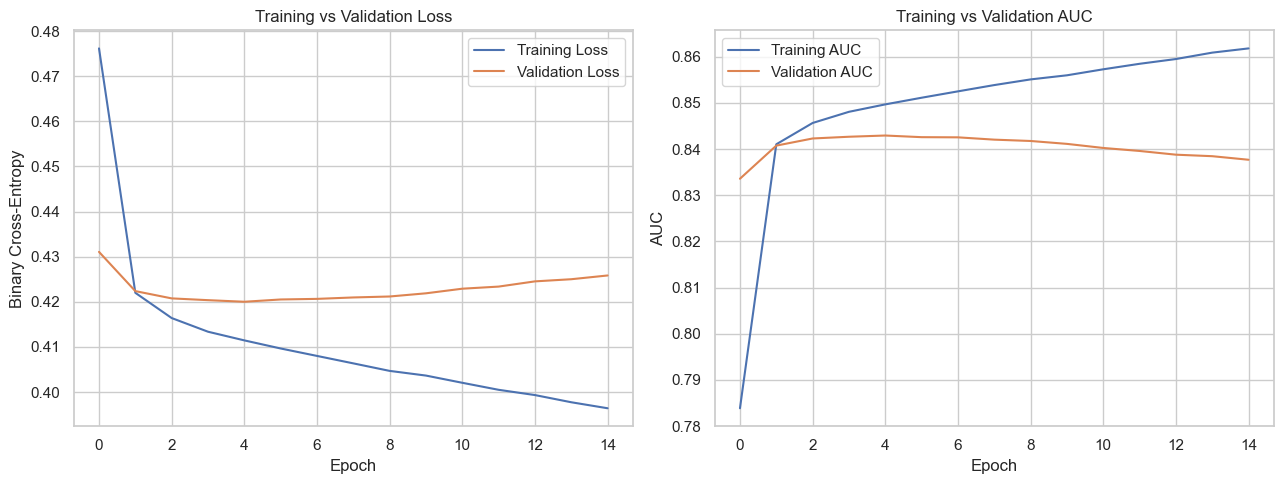

Best epoch: 5
Lowest validation loss: 0.42


In [27]:
# Convert training history into a DataFrame
history_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize = (13, 5))

# Training vs validation loss
axes[0].plot(history_df["loss"], label = "Training Loss")
axes[0].plot(history_df["val_loss"], label = "Validation Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy")
axes[0].legend()

# Training vs validation AUC
axes[1].plot(history_df["auc"], label = "Training AUC")
axes[1].plot(history_df["val_auc"], label = "Validation AUC")
axes[1].set_title("Training vs Validation AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("AUC")
axes[1].legend()

plt.tight_layout()
plt.show()

# Identify the epoch with the lowest validation loss
best_epoch = history_df["val_loss"].idxmin() + 1

print("Best epoch:", best_epoch)
print(
    "Lowest validation loss:",
    round(history_df["val_loss"].min(), 4)
)

**How should we interpret the charts?**

**Healthy learning**: Training and validation loss both decrease, then stabilize. Validation AUC improves and eventually plateaus.

**Potential overfitting**: Training loss continues decreasing while validation loss starts increasing. The network may be fitting noise or patterns specific to training customers.

**Potential underfitting**: Both training and validation performance remain poor, suggesting the model may not be learning enough useful structure.

These patterns are diagnostic signals, not definitive conclusions. We'll need to compare the neural network's validation metrics against our Logistic Regression baseline before deciding whether it's better.

## 10. Neural Network Evaluation & Model Comparison

### Objective

We'll evaluate the Keras neural network using the same validation dataset and classification threshold as our Logistic Regression baseline.

This ensures a consistent comparison between the two models.

### Evaluation Metrics

We'll compare five metrics:

1. **Accuracy:** Percentage of all customers classified correctly.
2. **Precision:** Percentage of predicted churners who actually churned.
3. **Recall:** Percentage of actual churners successfully identified.
4. **F1-score:** Harmonic mean of precision and recall.
5. **ROC-AUC:** Measures the model's ability to rank churners above non-churners across different classification thresholds.

### Why Compare Multiple Metrics?

Our dataset contains more retained customers than churned customers.

A model could achieve relatively high accuracy by predicting that most customers will remain, while failing to identify customers at risk of churn.

For a retention-focused business problem, recall and precision are particularly important.

We'll initially evaluate both models using a **0.50 classification threshold**.

Later, we'll investigate whether changing this threshold improves the balance between identifying churners and limiting unnecessary outreach.

### Evaluation Principle

All model comparisons in this section use the validation dataset.

We'll reserve the test dataset for final evaluation after model and threshold selection.

In [28]:
# Predict churn probabilities using the neural network
y_val_proba_nn = nn_model.predict(
    X_val_processed,
    verbose=0
).ravel()

# Apply the same 0.50 threshold used for Logistic Regression
y_val_pred_nn = (y_val_proba_nn >= 0.50).astype(int)

# Calculate neural network evaluation metrics
nn_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred_nn),
    "Precision": precision_score(
        y_val, y_val_pred_nn, zero_division=0
    ),
    "Recall": recall_score(y_val, y_val_pred_nn),
    "F1 Score": f1_score(y_val, y_val_pred_nn),
    "ROC-AUC": roc_auc_score(y_val, y_val_proba_nn)
}

display(
    pd.DataFrame(
        nn_metrics.items(),
        columns=["Metric", "Score"]
    ).round(4)
)

print(classification_report(
    y_val,
    y_val_pred_nn,
    target_names=["Retained", "Churned"]
))


,Metric,Score
0,Accuracy,0.7973
1,Precision,0.6447
2,Recall,0.5250
3,F1 Score,0.5787
4,ROC-AUC,0.8431


              precision    recall  f1-score   support

    Retained       0.84      0.90      0.87       776
     Churned       0.64      0.53      0.58       280

    accuracy                           0.80      1056
   macro avg       0.74      0.71      0.72      1056
weighted avg       0.79      0.80      0.79      1056



**Why use `.ravel()`?**

Unlike Scikit-learn's `predict_proba()`, our Keras model returns predictions in a two-dimensional array with shape `(n_customers, 1)`. `.ravel()` converts this into a one-dimensional array, making it compatible with Scikit-learn's evaluation functions.

**What should you examine?**

Pay particular attention to whether the neural network achieves higher recall or ROC-AUC than Logistic Regression. A neural network that improves accuracy but substantially reduces recall may not be preferable for identifying at-risk customers.

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Logistic Regression,0.8059,0.6459,0.5929,0.6182,0.8453
Keras Neural Network,0.7973,0.6447,0.5250,0.5787,0.8431
Difference (NN - LR),-0.0085,-0.0012,-0.0679,-0.0395,-0.0022


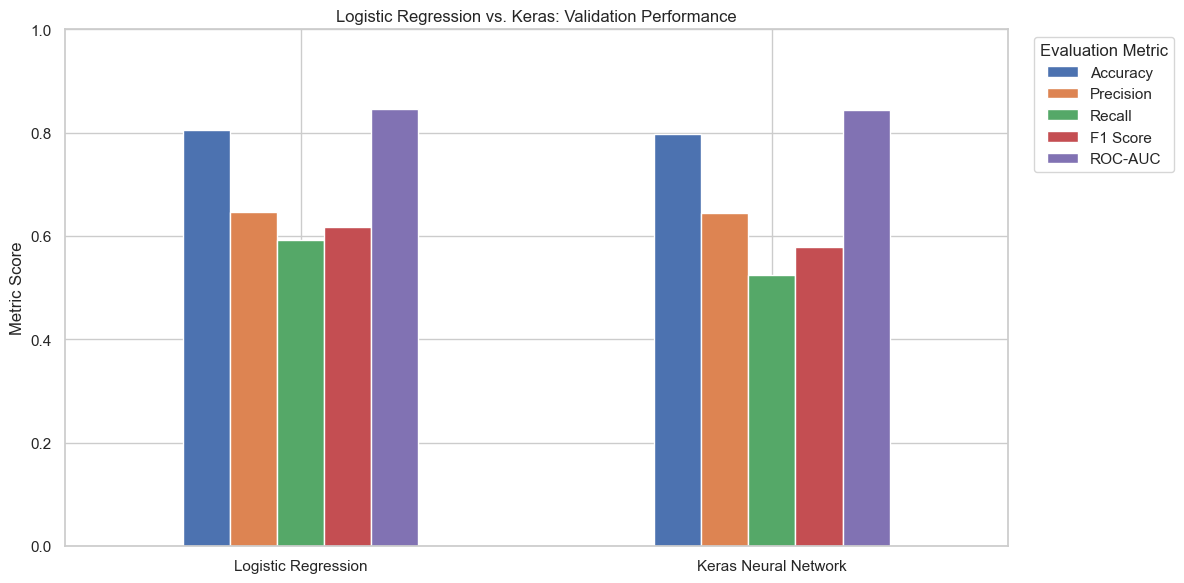

In [29]:
# Combine validation metrics from both models
comparison_df = pd.DataFrame({
    "Logistic Regression": lr_metrics,
    "Keras Neural Network": nn_metrics
}).T

# Calculate performance difference (Keras minus Logistic)
comparison_df.loc["Difference (NN - LR)"] = (
    comparison_df.loc["Keras Neural Network"]
    - comparison_df.loc["Logistic Regression"]
)

display(comparison_df.round(4))

# Visualize model performance
plot_df = comparison_df.drop("Difference (NN - LR)")

plot_df.plot(
    kind = "bar",
    figsize = (12, 6),
    rot = 0
)

plt.title("Logistic Regression vs. Keras: Validation Performance")
plt.ylabel("Metric Score")
plt.ylim(0, 1)
plt.legend(title = "Evaluation Metric", bbox_to_anchor = (1.02, 1))
plt.tight_layout()
plt.show()


### How Should We Interpret the Comparison?

Our goal isn't simply to identify which model has the highest accuracy.

Consider three possible outcomes:

| Observation | Interpretation |
|---|---|
| Neural network improves ROC-AUC | It may rank churners more effectively. |
| Neural network improves recall but lowers precision | It identifies more churners but produces more false positives. |
| Logistic Regression performs similarly | The simpler, more interpretable model may be preferable. |

**Important:** A small difference in validation performance doesn't necessarily mean one model is genuinely superior.

With a relatively small validation dataset, some differences may be due to sampling variability.

We'll consider this when making our final recommendation.

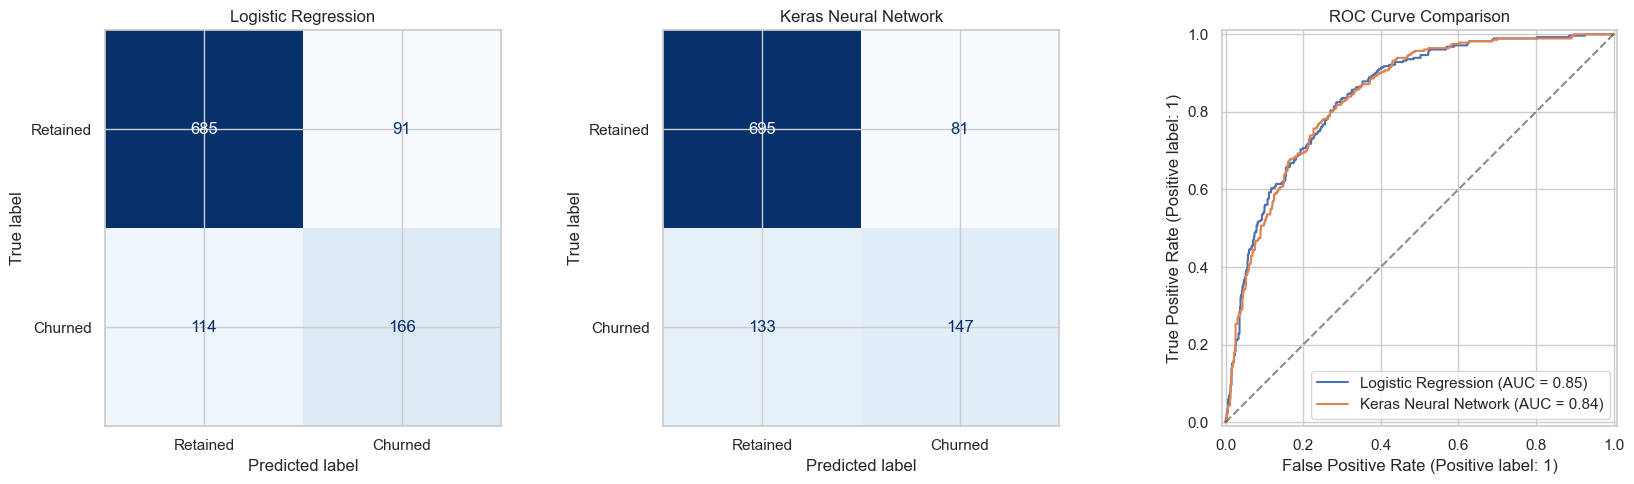

In [30]:
from sklearn.metrics import (RocCurveDisplay, ConfusionMatrixDisplay)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Logistic Regression confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_lr,
    display_labels = ["Retained", "Churned"],
    cmap = "Blues",
    ax = axes[0],
    colorbar = False
)
axes[0].set_title("Logistic Regression")

# Neural Network confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_nn,
    display_labels = ["Retained", "Churned"],
    cmap = "Blues",
    ax = axes[1],
    colorbar = False
)
axes[1].set_title("Keras Neural Network")

# Compare ROC curves
RocCurveDisplay.from_predictions(
    y_val,
    y_val_proba_lr,
    name = "Logistic Regression",
    ax = axes[2]
)

RocCurveDisplay.from_predictions(
    y_val,
    y_val_proba_nn,
    name = "Keras Neural Network",
    ax = axes[2]
)

axes[2].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[2].set_title("ROC Curve Comparison")

plt.tight_layout()
plt.show()

**What should we look for?**

**Confusion matrices**: Compare the number of false negatives and false positives between the two models. For churn prediction:
- Fewer false negatives mean more actual churners are identified.
- Fewer false positives mean fewer retained customers are unnecessarily flagged.

**ROC curves**

A curve closer to the top-left corner generally indicates better discrimination. If the curves overlap substantially, the neural network may not provide a meaningful improvement over Logistic Regression.

### Model Comparison: Key Findings

We trained and evaluated two classification models:

- **Logistic Regression:** A simpler, interpretable baseline.
- **Keras Neural Network:** A more flexible model capable of learning nonlinear relationships.

Both models were evaluated on the same validation dataset using a classification threshold of 0.50.

### Questions to Answer From Our Results

**1. Which model achieved the highest ROC-AUC?**

Compare their ability to distinguish customers who churn from those who remain.

**2. Which model achieved better recall?**

Determine which model identified a greater proportion of actual churners.

**3. What was the precision-recall trade-off?**

Assess whether improvements in recall resulted in additional false positives.

**4. Did the neural network justify its additional complexity?**

Consider whether its performance improvement is substantial enough to outweigh reduced interpretability and greater implementation complexity.

### Business Implications

The models can estimate churn risk and potentially help prioritize customers for retention outreach.

However, predictive accuracy alone does not establish the financial value of a retention strategy.

Business value also depends on:

- The cost of contacting customers.
- The value of retaining a customer.
- The likelihood that an intervention actually changes customer behavior.
- The number of customers the business can contact.

### Next Steps

We'll investigate classification threshold optimization to determine whether adjusting the decision boundary produces a more useful balance between precision and recall.

After selecting our final modeling approach, we'll evaluate it once on the untouched test dataset.

## 11. Classification Threshold Optimization

### Objective

Our models generate churn probabilities between 0 and 1.

By default, we've classified customers as likely to churn when their predicted probability is at least 0.50.

However, this threshold is not necessarily optimal for customer retention.

### How Does the Threshold Affect Predictions?

Consider a customer with a predicted churn probability of 0.42.

- **Threshold = 0.50:** Classified as retained.
- **Threshold = 0.40:** Classified as churned.
- **Threshold = 0.30:** Classified as churned.

Lowering the classification threshold generally increases recall but reduces precision.

Raising the threshold generally increases precision but reduces recall.

### Business Trade-offs

**Lower Threshold:**

- Identifies more potentially at-risk customers.
- Reduces false negatives.
- Increases the number of customers flagged for outreach.
- May increase retention campaign costs.

**Higher Threshold:**

- Focuses outreach on customers with stronger predicted churn risk.
- Generally reduces false positives.
- Requires fewer customer contacts.
- May miss customers who would otherwise benefit from intervention.

### Our Optimization Strategy

We'll compare several classification thresholds and select the one that maximizes F1-score on the validation dataset.

F1-score balances precision and recall, making it a useful starting objective when both missed churners and unnecessary outreach matter.

However, F1-score does not directly measure financial impact. A production retention strategy should ultimately consider campaign costs, customer value, and intervention effectiveness.

We'll keep the test dataset untouched until the final evaluation.

In [31]:
# We'll begin with the neural network's validation probabilities
# Define thresholds to evaluate
thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:
    # Convert probabilities into churn predictions
    y_pred = (y_val_proba_nn >= threshold).astype(int)

    # Calculate classification metrics
    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "Customers Flagged": int(y_pred.sum())
    })

# Create comparison table
threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1 Score,Customers Flagged
0,0.10,0.3976,0.9643,0.5631,679
1,0.15,0.4375,0.9250,0.5940,592
2,0.20,0.4621,0.8714,0.6040,528
3,0.25,0.4968,0.8250,0.6201,465
4,0.30,0.5304,0.7786,0.6310,411
5,0.35,0.5464,0.7143,0.6192,366
6,0.40,0.5864,0.6786,0.6291,324
7,0.45,0.6131,0.6000,0.6065,274
8,0.50,0.6447,0.5250,0.5787,228
9,0.55,0.6845,0.4571,0.5482,187


**What are we doing here?**

Rather than retraining the neural network, we're changing how its existing probability predictions are converted into classifications. For each threshold, we calculate:
- Precision: How many flagged customers actually churned?
- Recall: How many actual churners did we identify?
- F1-score: How well are precision and recall balanced?
- Customers Flagged: How many customers would be targeted for retention outreach?
  
The last metric is particularly important because it connects model predictions to potential operational workload.

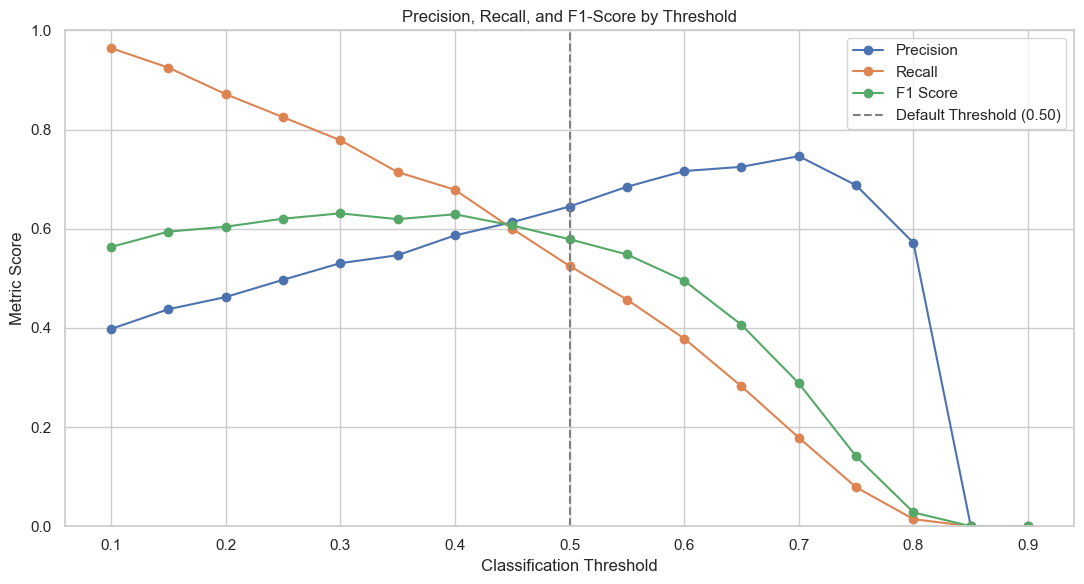

In [32]:
# Plot how metrics change with the classification threshold
plt.figure(figsize = (11, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker = "o",
    label = "Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker = "o",
    label = "Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1 Score"],
    marker = "o",
    label = "F1 Score"
)

plt.axvline(
    x = 0.50,
    linestyle = "--",
    color = "gray",
    label = "Default Threshold (0.50)"
)

plt.title("Precision, Recall, and F1-Score by Threshold")
plt.xlabel("Classification Threshold")
plt.ylabel("Metric Score")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

### How Should We Interpret the Chart?

The three curves help us understand how the model's behavior changes.

| Metric | What to Look For |
|---|---|
| **Precision** | Does targeting fewer customers improve the proportion who actually churn? |
| **Recall** | How many churners do we miss as the threshold increases? |
| **F1-score** | Which threshold provides the strongest balance between precision and recall? |

**Business Example:** A company with limited retention resources may prioritize precision, while a company focused on identifying as many churners as possible may prioritize recall.

Neither strategy is automatically better. The right decision depends on the business objective.

In [33]:
# Select the threshold with the highest validation F1-score
best_idx = threshold_df["F1 Score"].idxmax()

best_threshold = float(
    threshold_df.loc[best_idx, "Threshold"]
)

# Generate predictions using the selected threshold
y_val_pred_nn_optimized = (
    y_val_proba_nn >= best_threshold
).astype(int)

print(f"Optimal threshold: {best_threshold:.2f}")

# Compare the default and optimized thresholds
threshold_comparison = pd.DataFrame({
    "Default (0.50)": {
        "Precision": precision_score(
            y_val, y_val_pred_nn, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred_nn, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, y_val_pred_nn, zero_division=0
        ),
        "Customers Flagged": int(y_val_pred_nn.sum())
    },
    "Optimized": {
        "Precision": precision_score(
            y_val, y_val_pred_nn_optimized, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred_nn_optimized, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, y_val_pred_nn_optimized, zero_division=0
        ),
        "Customers Flagged": int(
            y_val_pred_nn_optimized.sum()
        )
    }
}).T

display(threshold_comparison.round(4))

Optimal threshold: 0.30


,Precision,Recall,F1 Score,Customers Flagged
Default (0.50),0.6447,0.5250,0.5787,228.0
Optimized,0.5304,0.7786,0.6310,411.0


**What should we look for?**

Compare the optimized threshold against the default of 0.50. Ask yourself:
1. Did the F1-score improve?
2. Did recall increase or decrease?
3. How much did precision change?
4. How many additional customers would need to be contacted?

Important: The selected threshold is optimal only for the F1-score objective and the thresholds we evaluated on this validation dataset. It is not necessarily the most profitable threshold for a real retention campaign. Also, because we've selected it using validation data, its validation F1-score may be somewhat optimistic. We'll assess generalization on the untouched test dataset in Part 10.

### Threshold Optimization: Business Interpretation

We evaluated classification thresholds between 0.10 and 0.90 to determine how the neural network's precision, recall, and F1-score change.

We selected the threshold that maximized F1-score on the validation dataset.

### Key Business Considerations

**1. Identifying At-Risk Customers**

Lower thresholds generally increase the proportion of actual churners identified, potentially creating more opportunities for retention intervention.

**2. Managing Outreach Costs**

Lower thresholds also tend to increase the number of customers flagged for outreach.

If retention campaigns involve discounts, incentives, or customer service costs, unnecessary outreach can reduce profitability.

**3. Balancing Precision and Recall**

A threshold optimized for F1-score balances two competing objectives:

- Identifying customers who are likely to churn.
- Avoiding excessive false-positive predictions.

**4. Predictive Performance vs. Business Impact**

A churn prediction model identifies customers at risk of leaving, but it does not tell us whether a retention offer will prevent their churn.

A future retention strategy could use randomized experiments to measure whether targeted outreach improves retention and generates incremental value.

### Next Steps

We'll evaluate our selected neural network and threshold on the untouched test dataset.

We'll also compare final performance against Logistic Regression and translate our findings into practical business recommendations.

The final model recommendation should consider predictive performance, interpretability, implementation complexity, and business usefulness.

## 12. Final Model Selection & Test Evaluation

### Objective

Our goal is to select the strongest churn prediction model, evaluate its generalization performance, and translate the results into actionable business recommendations.

We've trained two models:

1. **Logistic Regression:** A simpler, interpretable classification model.
2. **Keras Neural Network:** A nonlinear model capable of learning more complex relationships.

### Final Model Selection Strategy

To ensure a fair comparison, we'll optimize the classification threshold for both models using the same validation dataset and F1-score objective.

We'll then compare their optimized validation F1-scores.

If the models perform similarly, we'll favor Logistic Regression because it is simpler to interpret, maintain, and deploy.

Once we've selected a model and threshold, we'll evaluate that configuration on the untouched test dataset.

### Why Is the Test Dataset Important?

The training dataset was used to learn model parameters.

The validation dataset was used to monitor training, compare models, and optimize thresholds.

The test dataset provides a final estimate of how our selected approach performs on unseen customers.

We must not use test results to select a different model or adjust its threshold.

### Evaluation Metrics

We'll report:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion matrix

We'll also examine the number of customers flagged for retention outreach.

**Important:** Predictive performance measures how well we identify churn risk. It does not directly measure how many customers a retention campaign would successfully retain.

In [34]:
# Use the same threshold grid for both models
thresholds = np.arange(0.10, 0.91, 0.05)

def find_best_threshold(y_true, probabilities, thresholds):
    results = []

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        results.append({
            "Threshold": round(float(threshold), 2),
            "F1 Score": f1_score(
                y_true, predictions, zero_division=0
            )
        })

    results_df = pd.DataFrame(results)
    best_row = results_df.loc[results_df["F1 Score"].idxmax()]

    return float(best_row["Threshold"]), float(best_row["F1 Score"])


# Optimize both models on validation data
lr_threshold, lr_best_f1 = find_best_threshold(
    y_val, y_val_proba_lr, thresholds
)

nn_threshold, nn_best_f1 = find_best_threshold(
    y_val, y_val_proba_nn, thresholds
)

selection_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Keras Neural Network"],
    "Optimal Threshold": [lr_threshold, nn_threshold],
    "Validation F1": [lr_best_f1, nn_best_f1]
})

display(selection_df.round(4))

# Prefer the simpler model if F1 differences are within 0.01
if nn_best_f1 > lr_best_f1 + 0.01:
    selected_model = "Keras Neural Network"
    selected_threshold = nn_threshold
else:
    selected_model = "Logistic Regression"
    selected_threshold = lr_threshold

print(f"Selected model: {selected_model}")
print(f"Selected threshold: {selected_threshold:.2f}")

,Model,Optimal Threshold,Validation F1
0,Logistic Regression,0.45,0.6267
1,Keras Neural Network,0.30,0.6310


Selected model: Logistic Regression
Selected threshold: 0.45


**Understanding the selection logic**

We're using a consistent decision rule:
- If the neural network's validation F1-score exceeds Logistic Regression's by more than 0.01, select the neural network.
- Otherwise, prefer Logistic Regression for simplicity and interpretability.

The 0.01 tolerance is a practical heuristic, not a statistical significance test. It represents our willingness to accept a small performance difference in exchange for a simpler model. This rule is defined before examining the test dataset. Notice that we're using the same validation records and threshold candidates for both models.

In [35]:
# Generate test probabilities using the selected model
if selected_model == "Keras Neural Network":
    y_test_proba = nn_model.predict(
        X_test_processed, verbose=0
    ).ravel()
else:
    y_test_proba = log_reg.predict_proba(
        X_test_processed
    )[:, 1]

# Apply the threshold selected on validation data
y_test_pred = (
    y_test_proba >= selected_threshold
).astype(int)

# Calculate final test metrics
test_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(
        y_test, y_test_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_test_pred, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, y_test_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, y_test_proba)
}

test_results = pd.DataFrame(
    test_metrics.items(),
    columns=["Metric", "Test Score"]
)

print("Final Model:", selected_model)
print("Selected Threshold:", selected_threshold)

display(test_results.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Retained", "Churned"]
))

Final Model: Logistic Regression
Selected Threshold: 0.45


,Metric,Test Score
0,Accuracy,0.7966
1,Precision,0.6213
2,Recall,0.6014
3,F1 Score,0.6112
4,ROC-AUC,0.8447



Classification Report:
              precision    recall  f1-score   support

    Retained       0.86      0.87      0.86       776
     Churned       0.62      0.60      0.61       281

    accuracy                           0.80      1057
   macro avg       0.74      0.73      0.74      1057
weighted avg       0.79      0.80      0.80      1057



**What should we examine?**

Recall: What proportion of actual churners did our selected model identify?

Precision: Of the customers flagged as at risk, what proportion actually churned?

ROC-AUC: How effectively does the model distinguish churners from retained customers?

F1-score: How well does the selected threshold balance precision and recall?

Compare these results with your validation results. Some differences are expected because the datasets contain different customers. We should report the test results as observed rather than changing the model to improve them.

,Metric,Count
0,Customers Evaluated,1057
1,Actual Churners,281
2,Customers Flagged for Outreach,272
3,Churners Correctly Identified,169
4,Churners Missed,112
5,Retained Customers Incorrectly Flagged,103


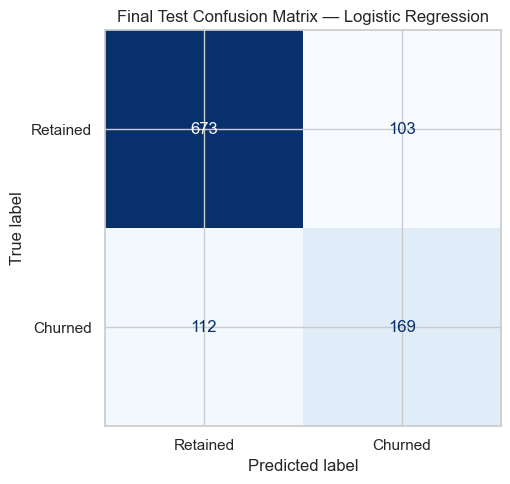

Customers flagged for outreach: 25.7%
Correctly identified churners: 169
Missed churners: 112
False-positive outreach candidates: 103


In [36]:
from sklearn.metrics import confusion_matrix

# Extract confusion matrix values
tn, fp, fn, tp = confusion_matrix(
    y_test, y_test_pred, labels=[0, 1]
).ravel()

# Summarize operational implications
business_summary = pd.DataFrame({
    "Metric": [
        "Customers Evaluated",
        "Actual Churners",
        "Customers Flagged for Outreach",
        "Churners Correctly Identified",
        "Churners Missed",
        "Retained Customers Incorrectly Flagged"
    ],
    "Count": [
        len(y_test),
        int(y_test.sum()),
        int(y_test_pred.sum()),
        int(tp),
        int(fn),
        int(fp)
    ]
})

display(business_summary)

# Visualize final confusion matrix
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Retained", "Churned"],
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title(f"Final Test Confusion Matrix — {selected_model}")

plt.tight_layout()
plt.show()

# Calculate the percentage of customers flagged
outreach_rate = y_test_pred.mean() * 100

print(f"Customers flagged for outreach: {outreach_rate:.1f}%")
print(f"Correctly identified churners: {tp}")
print(f"Missed churners: {fn}")
print(f"False-positive outreach candidates: {fp}")

**Why is this important?**

Technical metrics such as F1-score and ROC-AUC are valuable, but business stakeholders also need to understand the operational implications.
For example, if our model flags 30% of customers for outreach, the business needs to consider whether its retention team can realistically contact that many customers.

Likewise, if many flagged customers would not have churned, offering discounts to everyone could be expensive. The confusion matrix helps quantify these trade-offs. However, true positives are correctly identified churners, not customers proven to have been saved. Measuring actual retention impact requires an intervention and a suitable comparison group.

## 13. Business Recommendations & Conclusion

### Project Objective

The objective of this project was to develop a machine learning solution capable of identifying customers at risk of churn and supporting more targeted customer retention strategies.

### Methodology

We completed the following steps:

1. Conducted exploratory data analysis to investigate customer churn patterns.
2. Cleaned and preprocessed numerical and categorical features.
3. Split the dataset into training, validation, and test sets.
4. Trained Logistic Regression as a baseline classification model.
5. Built and trained an Artificial Neural Network using Keras.
6. Compared model performance using multiple classification metrics.
7. Optimized classification thresholds using validation F1-score.
8. Selected a final model and evaluated it on unseen test data.

### Key Findings

The final results should be interpreted using the model comparison table, test evaluation metrics, and confusion matrix generated above.

In particular, we should report:

- The selected model and classification threshold.
- Its final test ROC-AUC and F1-score.
- The proportion of actual churners successfully identified.
- The number of customers flagged for retention outreach.
- The trade-off between missed churners and unnecessary outreach.

### Business Recommendations

**1. Prioritize Retention Outreach Using Churn Risk**

Use predicted churn probabilities to segment customers into risk groups and prioritize outreach according to available resources.

**2. Tailor Retention Strategies to Customer Characteristics**

Use exploratory findings to identify customer segments associated with elevated churn risk, such as particular contract types, tenure groups, or service combinations.

These patterns are associations and should not automatically be interpreted as causal drivers.

**3. Validate Retention Campaign Effectiveness Through A/B Testing**

Conduct randomized experiments to determine whether targeted interventions actually reduce churn.

Measure incremental retention, campaign costs, and customer value rather than relying exclusively on predictive accuracy.

**4. Monitor Model Performance Over Time**

Track changes in churn rates, prediction quality, customer characteristics, and outreach volumes.

Retrain or recalibrate the model when performance meaningfully deteriorates.

### Limitations

- The dataset is relatively small and represents a particular telecommunications customer population.
- Model performance may differ across other companies or time periods.
- The dataset does not establish whether a retention offer would change a customer's behavior.
- Threshold optimization used F1-score rather than a measured financial objective.
- The test results provide an estimate of predictive generalization, not proven campaign effectiveness.

### Conclusion

This project demonstrates an end-to-end machine learning workflow combining exploratory analysis, feature preprocessing, Logistic Regression, neural network modeling, threshold optimization, and business interpretation.

The final model can help identify customers at elevated churn risk and support retention prioritization.

However, the next step toward measurable business value would be to test whether model-guided interventions improve customer retention and generate positive incremental returns.

In [37]:
# Portfolio summary: model selection and final performance

print("=" * 55)
print("CUSTOMER CHURN PREDICTION — FINAL RESULTS")
print("=" * 55)

print(f"\nSelected Model: {selected_model}")
print(f"Classification Threshold: {selected_threshold:.2f}")

print("\nVALIDATION MODEL COMPARISON")
print(selection_df.round(4).to_string(index=False))

print("\nFINAL TEST PERFORMANCE")
print(test_results.round(4).to_string(index=False))

print("\nBUSINESS IMPACT METRICS")
print(business_summary.to_string(index=False))

print("\nCUSTOMER OUTREACH")
print(f"Outreach Rate: {outreach_rate:.1f}%")
print(f"True Positives: {tp}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Negatives: {tn}")


CUSTOMER CHURN PREDICTION — FINAL RESULTS

Selected Model: Logistic Regression
Classification Threshold: 0.45

VALIDATION MODEL COMPARISON
               Model  Optimal Threshold  Validation F1
 Logistic Regression               0.45         0.6267
Keras Neural Network               0.30         0.6310

FINAL TEST PERFORMANCE
   Metric  Test Score
 Accuracy      0.7966
Precision      0.6213
   Recall      0.6014
 F1 Score      0.6112
  ROC-AUC      0.8447

BUSINESS IMPACT METRICS
                                Metric  Count
                   Customers Evaluated   1057
                       Actual Churners    281
        Customers Flagged for Outreach    272
         Churners Correctly Identified    169
                       Churners Missed    112
Retained Customers Incorrectly Flagged    103

CUSTOMER OUTREACH
Outreach Rate: 25.7%
True Positives: 169
False Positives: 103
False Negatives: 112
True Negatives: 673


## 14. Final Model Results & Business Interpretation

### Model Selection

We compared Logistic Regression and a Keras neural network using validation F1-score after classification threshold optimization.

- **Logistic Regression:** Validation F1 = 0.6267, threshold = 0.45
- **Keras Neural Network:** Validation F1 = 0.6310, threshold = 0.30

Although the neural network achieved a marginally higher F1-score, the improvement of 0.0043 did not exceed our predefined complexity tolerance of 0.01.

We therefore selected Logistic Regression as the final model because of its comparable predictive performance, interpretability, and simpler implementation.

### Final Test Performance

| Metric | Result |
|---|---:|
| Accuracy | 79.66% |
| Precision | 62.13% |
| Recall | 60.14% |
| F1-score | 0.6112 |
| ROC-AUC | 0.8447 |
| Classification Threshold | 0.45 |

### Business Interpretation

The model evaluated 1,057 customers and flagged 272 (25.7%) as potentially at risk of churn.

Of those flagged:

- **169 customers** actually churned.
- **103 customers** remained, representing false positives.

The model also missed 112 of the 281 actual churners.

Overall, it successfully identified approximately 60% of churners while limiting potential outreach to approximately one-quarter of the customer base.

### Key Findings

**1. Simpler Models Can Deliver Competitive Performance**

The Keras neural network did not demonstrate sufficient validation improvement to justify its additional complexity under our model selection criterion.

**2. Churn Risk Can Support Targeted Outreach**

The selected model demonstrated useful discriminatory performance (ROC-AUC = 0.8447), suggesting that predicted churn risk could help prioritize retention efforts.

**3. Predictive Performance Does Not Equal Retention Impact**

The model identifies customers likely to churn, but additional experimentation is necessary to determine whether retention campaigns would prevent churn.

### Business Recommendations

1. **Prioritize high-risk customers:** Use churn probabilities to guide retention outreach, accounting for campaign capacity and customer value.
2. **Tailor interventions:** Investigate contract type, tenure, and service-related churn patterns to inform customer segmentation.
3. **Measure incremental impact:** Conduct A/B tests to evaluate whether targeted offers reduce churn and generate positive financial returns.
4. **Monitor performance:** Track model discrimination, precision, recall, and changes in customer behavior over time.

### Conclusion

This project demonstrates an end-to-end churn prediction workflow, including exploratory data analysis, preprocessing, Logistic Regression, neural network training, threshold optimization, and final test evaluation.

The selected Logistic Regression model achieved a test ROC-AUC of 0.8447 and identified 60.14% of actual churners while flagging 25.7% of customers for potential outreach.

The results support using churn predictions as a tool for retention prioritization, subject to further validation of real-world campaign effectiveness.

In [38]:
from pathlib import Path

# Save charts to a folder in your Downloads directory
images_dir = Path.home() / "Downloads" / "churn_project_images"

images_dir.mkdir(parents=True, exist_ok=True)

print("Images will be saved to:", images_dir.resolve())


Images will be saved to: C:\Users\GamerTech\Downloads\churn_project_images


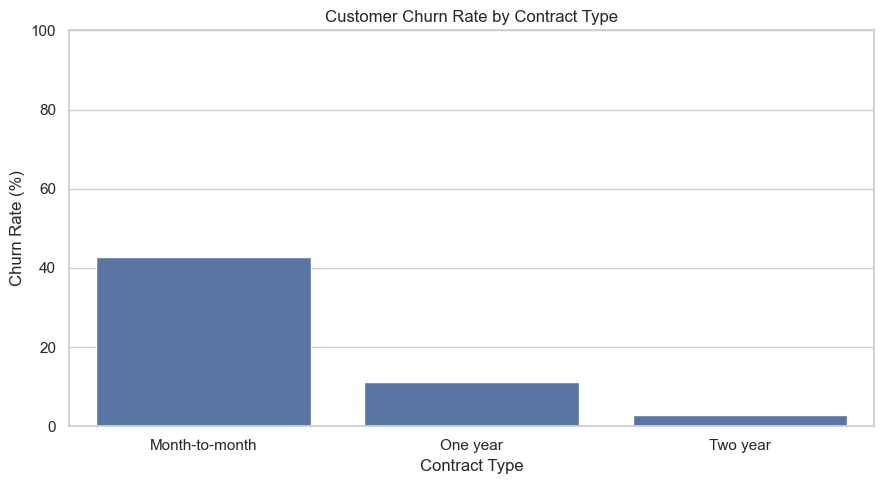

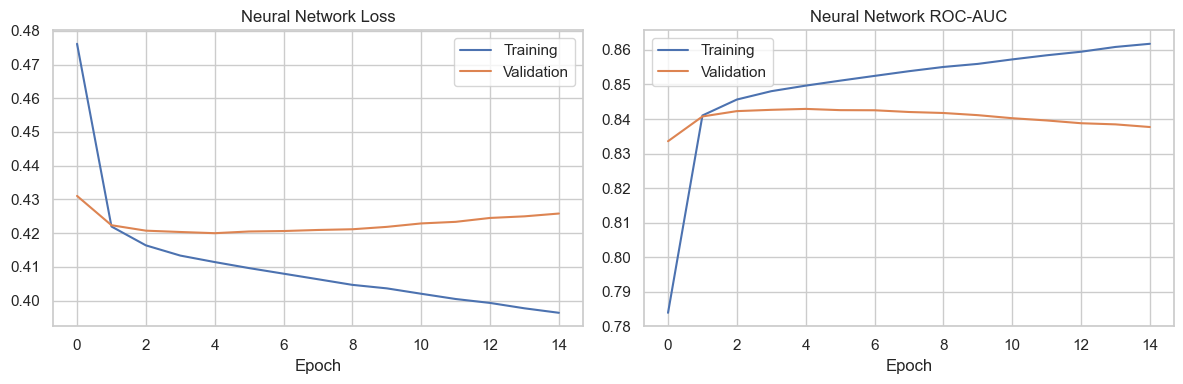

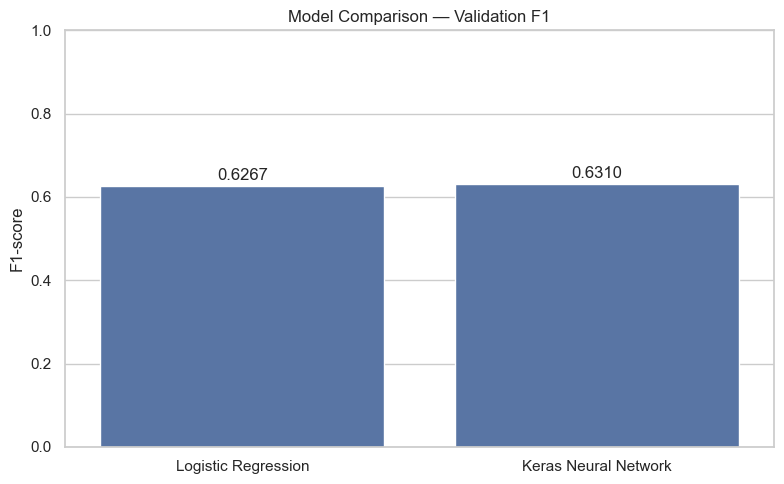

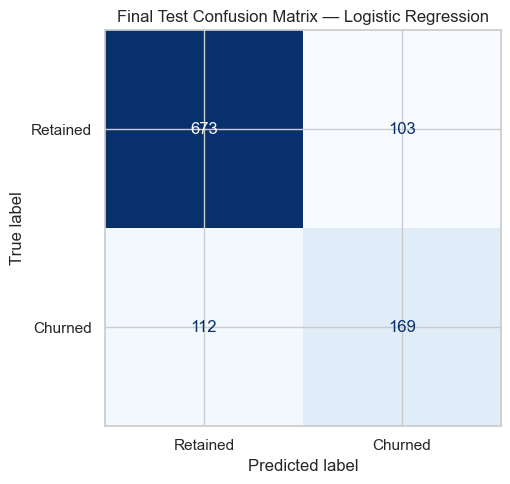

All four charts saved to: C:\Users\GamerTech\Downloads\churn_project_images


In [39]:

from sklearn.metrics import ConfusionMatrixDisplay

# 1. Churn Rate by Contract Type
contract_churn = (
    df.groupby("Contract")["ChurnFlag"]
    .mean()
    .sort_values(ascending=False)
    .mul(100)
)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=contract_churn.index, y=contract_churn.values, ax=ax)

ax.set_title("Customer Churn Rate by Contract Type")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, 100)

plt.tight_layout()
fig.savefig(images_dir / "churn_by_contract.png", dpi=200)
plt.show()


# 2. Neural Network Training History
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["loss"], label="Training")
axes[0].plot(history_df["val_loss"], label="Validation")
axes[0].set_title("Neural Network Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history_df["auc"], label="Training")
axes[1].plot(history_df["val_auc"], label="Validation")
axes[1].set_title("Neural Network ROC-AUC")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
fig.savefig(images_dir / "training_history.png", dpi=200)
plt.show()


# 3. Model Comparison
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=selection_df,
    x="Model",
    y="Validation F1",
    ax=ax
)

ax.set_title("Model Comparison — Validation F1")
ax.set_xlabel("")
ax.set_ylabel("F1-score")
ax.set_ylim(0, 1)

for i, value in enumerate(selection_df["Validation F1"]):
    ax.text(i, value + 0.015, f"{value:.4f}", ha="center")

plt.tight_layout()
fig.savefig(images_dir / "model_comparison.png", dpi=200)
plt.show()


# 4. Final Test Confusion Matrix
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Retained", "Churned"],
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title(f"Final Test Confusion Matrix — {selected_model}")

plt.tight_layout()
fig.savefig(images_dir / "final_confusion_matrix.png", dpi=200)
plt.show()

print("All four charts saved to:", images_dir.resolve())